<a href="https://colab.research.google.com/github/JaCaRego/JaCaRego/blob/main/Profissao_Cientista_de_Dados_M13_Projeto_Jales1.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 5 - Revelando os Padrões de Desconto: Um Mapa Interativo por Categoria e Marca

# **MÓDULO 13**
# Projeto Final: Desvendando os Segredos dos Dados de Supermercado

Nesta emocionante jornada, mergulharemos fundo nos dados de produtos de um vibrante supermercado chileno. Nosso objetivo? Aplicar os poderosos conceitos estatísticos e as técnicas de visualização de dados que aprendemos, transformando números brutos em histórias convincentes. Ao final, levaremos nossas descobertas para o mundo, publicando-as no seu GitHub!

Prepare-se para desvendar os mistérios por trás dos preços, das marcas e dos descontos!

In [59]:
import pandas as pd
import matplotlib.pyplot as plt
import plotly.express as px

Nossa aventura começa com a importação dos dados. Localize o mapa do tesouro (o arquivo CSV) e carregue-o para o nosso laboratório de análise.

In [60]:
df = pd.read_csv('/content/MODULO7_PROJETOFINAL_BASE_SUPERMERCADO - MODULO7_PROJETOFINAL_BASE_SUPERMERCADO (1).csv.csv', delimiter=',')
df.head(10)

,title,Marca,Preco_Normal,Preco_Desconto,Preco_Anterior,Desconto,Categoria
0,"Pack 12 un, Leche extra proteína 1 L",Loncoleche,19788,0,0,0,lacteos
1,"Pack 12 un, Leche chocolate receta original 1 L",Soprole,18228,0,0,0,lacteos
2,"Pack 12 un, Leche semidescremada chocolate 1 L",Soprole,18228,0,0,0,lacteos
3,"Pack 12 un, Leche semidescremada frutilla 1 L",Soprole,18228,0,0,0,lacteos
4,"Pack 12 un, Leche sin lactosa chocolate 1 L",Loncoleche,17988,0,0,0,lacteos
5,"Pack 12 un, Leche sin lactosa frutilla 1 L",Loncoleche,17988,0,0,0,lacteos
6,"Pack 12 un, Leche saborizada light chocolate 1 L",Loncoleche,17988,0,0,0,lacteos
7,"Pack 12 un, Leche saborizada frutilla 1 L",Colun,17388,0,0,0,lacteos
8,"Pack 12 un, Leche saborizada vainilla 1 L",Colun,17388,0,0,0,lacteos
9,"Pack 12 un, Leche saborizada manjar 1 L",Colun,17388,0,0,0,lacteos


## O Dicionário dos Nossos Dados: Conhecendo os Personagens da Nossa História

Cada coluna em nosso conjunto de dados conta uma parte da história de cada produto. Vamos conhecer nossos principais protagonistas:

*   **Title:** O nome que identifica cada produto, sua essência.
*   **Marca:** A família à qual o produto pertence, seu sobrenome.
*   **Preco_Normal:** O preço de referência, a 'etiqueta cheia' quando não há promoções.
*   **Preco_Desconto:** O preço que o cliente realmente paga após uma oferta especial.
*   **Preco_Anterior:** Uma memória do passado, o preço praticado antes de qualquer alteração.
*   **Desconto:** O valor monetário da economia, o 'presente' para o consumidor.

### O Enigma dos Descontos Ausentes:

Um detalhe crucial em nossa narrativa: as colunas com valores **0** indicam produtos que, em nosso registro, não tiveram nenhum desconto aplicado. Elas nos contam uma história de preços fixos e consistentes.

Ah, e um toque de sabor internacional: as **Categorias** estão em espanhol! Um pequeno desafio para nossa imersão no cenário chileno.

# 1 - A Primeira Pista: Média e Mediana de Preços por Categoria

Nossa primeira missão é desvendar a paisagem dos preços. Vamos calcular a média e a mediana do 'Preco_Normal' para cada categoria de produto. Qual a 'centralidade' dos preços em cada grupo?

Em seguida, o desafio: identificar as categorias onde a média e a mediana contam histórias diferentes. Há grupos onde alguns produtos de alto valor puxam a média para cima, distorcendo a percepção do 'preço típico'? Ou será que produtos mais baratos as nivelam para baixo?

In [61]:
media_por_categoria = df.groupby('Categoria')['Preco_Normal'].mean()
print('Média por Categoria:')
print(media_por_categoria)

Média por Categoria:
Categoria
belleza-y-cuidado-personal    1783.556485
comidas-preparadas            3095.043478
congelados                    2108.042553
frutas                        1724.473684
instantaneos-y-sopas           765.491228
lacteos                       2385.219239
verduras                      1343.296875
Name: Preco_Normal, dtype: float64


In [82]:
mediana_por_categoria = df.groupby('Categoria')['Preco_Normal'].median()
print('\nMediana por Categoria:')
print(mediana_por_categoria)


Mediana por Categoria:
Categoria
belleza-y-cuidado-personal    1569.0
comidas-preparadas            3290.0
congelados                    1519.0
frutas                        1195.0
instantaneos-y-sopas           439.0
lacteos                        989.0
verduras                      1180.0
Name: Preco_Normal, dtype: float64


## Desvendando os Perfis de Preço: Média vs. Mediana

Ao comparar a média e a mediana do 'Preco_Normal' para cada categoria, notamos padrões intrigantes que nos dão as primeiras pistas sobre a distribuição dos preços:

*   **Beleza e Cuidado Pessoal:** A média supera a mediana. Isso sugere que alguns produtos mais luxuosos ou específicos estão elevando o patamar geral de preços, criando uma cauda à direita na distribuição.
*   **Comidas Preparadas:** Uma leve inversão! A média é um pouco menor que a mediana, indicando que pode haver mais opções de preços acessíveis, ou uma distribuição ligeiramente inclinada para a esquerda, com alguns itens mais baratos que a maioria.
*   **Congelados:** Aqui a média se distancia significativamente da mediana. É um sinal claro da presença de produtos com preços substancialmente mais altos, talvez itens especiais ou em maior volume, que aumentam a média da categoria.
*   **Frutas:** Similar a Beleza, a média é maior. Frutas exóticas ou orgânicas podem ser os 'vilões' que elevam essa média.
*   **Instantâneos e Sopas:** Novamente, a média é maior que a mediana, apontando para alguns itens premium ou com maior valor agregado que se destacam na prateleira.
*   **Lácteos:** Uma das maiores diferenças! A média é consideravelmente mais alta que a mediana. Esta categoria parece ser um campo fértil para produtos de alto valor, gerando uma grande dispersão de preços.
*   **Verduras:** A média é ligeiramente maior, sugerindo que alguns vegetais ou produtos especiais estão influenciando o preço médio.

### A Conclusão da Primeira Etapa:

Em geral, a maioria das categorias revela uma distribuição de preços com **assimetria positiva (cauda à direita)**, onde poucos produtos mais caros 'puxam' a média para cima. As categorias 'Congelados', 'Frutas', 'Instantâneos e Sopas' e 'Lácteos' são as que mais evidenciam essa disparidade, indicando que a exploração mais aprofundada desses grupos pode revelar os 'diamantes' e os 'desafios' do nosso inventário.

# 2 - Desvendando a Dispersão: O Desvio Padrão por Categoria

Após entender a 'centralidade' dos preços, nossa próxima etapa é medir a 'dispersão'. O desvio padrão nos dirá o quão variados são os preços dentro de cada categoria. Uma alta variação pode indicar tanto uma grande variedade de produtos quanto a presença de valores extremos.

Em seguida, vamos focar nossa lente na categoria com a maior dispersão. Como a média e a mediana se comportam nesse cenário de grande variação? Elas ainda contam a mesma história, ou a dispersão revela novos detalhes sobre a estrutura de preços?

In [84]:
desvio_padrao_por_categoria = df.groupby('Categoria')['Preco_Normal'].std()
print('Desvio Padrão por Categoria:')
print(desvio_padrao_por_categoria)

maior_desvio_categoria = desvio_padrao_por_categoria.idxmax()
print(f'\nCategoria com o maior desvio padrão: {maior_desvio_categoria}')
print(f'Média para {maior_desvio_categoria}: {media_por_categoria[maior_desvio_categoria]:.2f}')
print(f'Mediana para {maior_desvio_categoria}: {mediana_por_categoria[maior_desvio_categoria]:.2f}')

Desvio Padrão por Categoria:
Categoria
belleza-y-cuidado-personal    2210.041719
comidas-preparadas            2019.911428
congelados                    2111.539896
frutas                        1639.151114
instantaneos-y-sopas          1170.232869
lacteos                       3925.816164
verduras                      1012.699625
Name: Preco_Normal, dtype: float64

Categoria com o maior desvio padrão: lacteos
Média para lacteos: 2385.22
Mediana para lacteos: 989.00


## Lácteos: O Epicentro da Variação de Preços

Nossa investigação sobre a dispersão dos preços revela um protagonista claro: a categoria **Lácteos**, que apresenta o maior desvio padrão, com um valor expressivo de 3925.82. Este número nos diz que os preços dos produtos lácteos são os mais variados em todo o supermercado.

### Um Olhar Mais Atento em Lácteos:

*   **Média:** 2385.22
*   **Mediana:** 989.00

Aqui, o enredo se aprofunda: a média é **significativamente maior** que a mediana. Essa grande disparidade, combinada com o altíssimo desvio padrão, é um forte indicativo de que a distribuição dos preços em Lácteos é **altamente assimétrica**, com uma 'cauda longa' de produtos muito mais caros. Isso sugere a presença de **outliers de preços altos** – talvez queijos especiais, leites importados ou produtos gourmet – que elevam drasticamente a média da categoria, mas não representam o preço 'típico' da maioria dos itens lácteos. Lácteos é, portanto, uma categoria de contrastes, onde o luxo e o essencial convivem lado a lado, criando uma paisagem de preços complexa.

# 3 - Ampliando o Foco: Um Boxplot para Lácteos

Para visualizar a história dos preços em Lácteos de forma mais intuitiva, construiremos um **boxplot**. Este gráfico nos permitirá ver a distribuição dos dados, identificar a amplitude dos preços e, crucialmente, revelar a presença de **outliers** — aqueles pontos de dados que se desviam drasticamente da maioria.

Com base em nossa análise anterior, esperamos encontrar uma distribuição assimétrica e muitos pontos fora da 'caixa', confirmando a presença de produtos de alto valor que tornam Lácteos uma categoria tão diversificada em termos de preço.

Para aprofundar nossa análise na categoria 'Lácteos', vou gerar um boxplot do `Preco_Normal`. A expectativa é que este gráfico nos mostre visualmente a distribuição assimétrica e a presença notável de outliers, confirmando nossa hipótese de que há produtos com preços muito elevados nesta categoria.

In [64]:
df_lacteos = df.loc[df['Categoria'] == 'lacteos']
fig = px.box(df_lacteos, y="Preco_Normal", title=f'Boxplot de Preco_Normal para a categoria {maior_desvio_categoria}')
fig.show()

## A Revelação do Boxplot: Outliers e Assimetria em Lácteos

O boxplot da categoria 'Lácteos' foi revelado, e ele confirma nossa narrativa! Como antecipado, a distribuição do `Preco_Normal` para esta categoria é visivelmente **assimétrica à direita**, com uma **cauda superior longa** que se estende para valores muito mais altos. Este alongamento é acentuado pela presença de **muitos pontos de dados acima do 'bigode' superior**, que são os nossos **outliers**.

Esses outliers não são erros; são produtos de alto valor que, embora em menor quantidade, impactam fortemente a média da categoria, como já havíamos observado. O boxplot nos dá uma representação visual clara de que, em 'Lácteos', o preço 'típico' (mediana) é bem diferente do preço 'médio', e que há um segmento de produtos que se posiciona em um patamar de preço muito superior aos demais.

# 4 - A Busca pelos Descontos: Média por Categoria

Nossa quarta etapa nos leva a explorar o mundo das promoções. Queremos entender qual categoria oferece os maiores 'presentes' aos clientes. Para isso, construiremos um **gráfico de barras** que mostrará a **média de descontos** aplicada em cada categoria de produto.

Este gráfico será um termômetro das estratégias de precificação e das ofertas mais generosas do supermercado. Onde os clientes encontram as melhores oportunidades de economia?

In [65]:
desconto_por_categoria = df.groupby('Categoria')['Desconto'].mean().reset_index()
fig = px.bar(desconto_por_categoria, x='Categoria', y='Desconto', title='Média de Desconto por Categoria')
fig.show()

## O Panorama dos Descontos: Um Gráfico de Barras

Com o gráfico de barras da média de descontos por categoria em mãos, temos uma visão clara das promoções. A análise revela que:

*   A categoria **'Congelados'** se destaca como a mais generosa, apresentando a maior média de descontos.
*   Por outro lado, **'Frutas', 'Instantâneos e Sopas' e 'Verduras'** parecem ser os 'sem desconto', com uma média de zero. Isso reforça a ideia de que esses produtos são vendidos a preço cheio, ou que os descontos são raros ou inexistentes em nosso conjunto de dados para essas categorias.

Este gráfico é um valioso indicador de onde o supermercado foca suas campanhas de desconto, e onde os consumidores podem esperar encontrar as melhores barganhas.

# 5 - Desvendando os Descontos por Categoria e Marca: Um Mapa Interativo

Nossa última missão da etapa inicial é criar um **mapa interativo** que nos permitirá navegar pelos descontos em um nível mais granular. Queremos ver a média de descontos agrupada não apenas por categoria, mas também por marca.

Este treemap será um guia visual para identificar as 'ilhas' de maiores descontos, revelando quais combinações de categoria e marca são mais propensas a oferecer economias significativas. Prepare-se para explorar e descobrir os cantos mais vantajosos do supermercado!

In [66]:
df_mapa = df.groupby(['Categoria', 'Marca'])['Desconto'].mean().reset_index()
df_mapa_filtered = df_mapa[df_mapa['Desconto'] > 0]

fig = px.treemap(df_mapa_filtered, path=['Categoria', 'Marca'], values='Desconto',
                 title='Média de Desconto por Categoria e Marca (Somente Descontos > 0)',
                 color='Desconto', color_continuous_scale='Viridis')
fig.show()

## O Desafio do Treemap de Descontos e a Solução Criativa

Ao tentar gerar o treemap interativo, encontramos um pequeno obstáculo: a função `px.treemap` não consegue lidar com situações onde algumas categorias ou marcas não possuem descontos, resultando em uma média de desconto zero, o que pode causar erros como a divisão por zero ao tentar escalar os valores. Isso nos leva a um treemap vazio, o que não nos ajuda a contar a história dos descontos.

### A Virada na Nossa Estratégia:

Para contornar isso, adotei uma abordagem mais inteligente. Filtrei os dados para incluir **apenas as categorias e marcas que possuem uma média de desconto maior que zero**. Isso garante que nosso treemap seja preenchido apenas com informações relevantes e que possamos visualizar os descontos reais onde eles existem.

### O Treemap Revelado:

Agora, o treemap interativo está pronto! Ele nos mostra a média de desconto por categoria e marca, **excluindo os 'zeros' que obscureciam nossa visão**. Você pode interagir com ele, clicando nas categorias para expandir e ver as marcas, e nos próprios retângulos para detalhes. Isso nos permite identificar rapidamente onde as melhores ofertas de descontos se escondem, revelando os verdadeiros 'caçadores de barganhas' do supermercado.

## O Caminho Adiante: Estratégias para Refinar Nossos Dados e Desvendar Mais Histórias

Após nossa exploração inicial, que revelou assimetrias e a presença de outliers, especialmente na coluna `Preco_Normal` (com 'Lácteos' como um notável exemplo), é hora de refinar nossos dados para que possam nos contar histórias ainda mais precisas e serem a base para análises mais sofisticadas. Minhas recomendações para o tratamento e preparação dos dados seguem um roteiro estratégico:

### 1. Lidando com os Gigantes: O Tratamento de Outliers em `Preco_Normal`

**A Descoberta:** O boxplot de 'Lácteos' e a notável diferença entre média e mediana em várias categorias gritam a presença de valores extremos no `Preco_Normal`. Esses 'gigantes' podem distorcer nossas percepções e enganar modelos preditivos.

**Nossa Abordagem:** Em vez de simplesmente remover esses valores, que podem ser legítimos, sugiro o **'Capping'** (limitação). Vamos definir um limite (por exemplo, o 99º percentil) e ajustar os valores que o ultrapassam para esse limite. Isso 'doma' os gigantes sem ignorar sua existência, mantendo a integridade da maioria dos dados. A remoção seria uma alternativa se tivéssemos certeza de que são erros, mas o capping oferece uma solução mais suave.

### 2. Suavizando as Curvas: Tratamento da Assimetria em `Preco_Normal`

**A Descoberta:** A distribuição de `Preco_Normal` é claramente assimétrica à direita, com uma longa 'cauda' para preços mais altos. Muitos modelos de machine learning preferem dados com uma distribuição mais 'normal' ou simétrica.

**Nossa Abordagem:** Para 'suavizar' essa curva, aplicaremos uma **transformação logarítmica**. Isso tem o poder de comprimir os valores mais altos, aproximando a distribuição de uma forma mais simétrica e tornando os dados mais amigáveis para algoritmos que esperam essa característica. Isso revelará padrões que antes estavam obscurecidos pela magnitude dos valores.

### 3. Nivelando o Campo de Jogo: Normalização/Padronização de Features Numéricas

**A Descoberta:** Nossas colunas numéricas (`Preco_Normal`, `Preco_Desconto`, `Preco_Anterior` e `Desconto`) vivem em mundos de escalas muito diferentes. Em muitos algoritmos, uma feature com valores maiores pode dominar a análise, mesmo que não seja intrinsecamente mais importante.

**Nossa Abordagem:** Após o capping e a transformação logarítmica, **padronizaremos** essas colunas usando o `StandardScaler`. Isso transformará os dados para que tenham média zero e desvio padrão um, garantindo que todas as features numéricas contribuam igualmente para a análise, sem que a magnitude de seus valores as torne 'mais importantes'.

### 4. Traduzindo o Idioma: Codificação de Variáveis Categóricas

**A Descoberta:** 'Marca' e 'Categoria' são informações vitais, mas estão em formato de texto. A maioria dos algoritmos de machine learning, nossos 'intérpretes', só entende números.

**Nossa Abordagem:** Usaremos o **One-Hot Encoding** para transformar essas variáveis. Para cada categoria única, criaremos uma nova coluna binária (0 ou 1), permitindo que nossos algoritmos 'compreendam' e utilizem essas informações textuais sem assumir qualquer ordem artificial.

### 5. A Engenharia dos Descontos: Revelando o `Percentual_Desconto`

**A Descoberta:** Embora tenhamos a coluna 'Desconto', um 'Percentual_Desconto' pode ser uma métrica mais intuitiva para entender o impacto real das promoções e pode ser uma feature poderosa para modelos.

**Nossa Abordagem:** Calcularemos o `Percentual_Desconto = (Desconto / Preco_Normal) * 100`. Esta nova feature nos dará uma visão clara da profundidade das promoções, permitindo comparações mais justas entre produtos de diferentes valores.

### Em Resumo:

Este roteiro de tratamento de dados não é apenas uma série de passos técnicos; é a construção de uma base sólida para desvendar as histórias mais profundas e complexas que nossos dados de supermercado têm a contar, pavimentando o caminho para insights poderosos e até mesmo para a construção de modelos preditivos eficazes.

## Iniciando o Tratamento: Controlando os Outliers de `Preco_Normal` com Capping

Nossa primeira etapa crucial para refinar os dados é lidar com os 'gigantes' de preços que identificamos na coluna `Preco_Normal`. Para evitar que alguns valores extremamente altos distorçam nossas análises futuras, aplicaremos a técnica de **Capping**. Isso significa que todos os preços acima do 99º percentil serão 'limitados' ao valor desse percentil, garantindo que os extremos não dominem a história dos preços, mas sem remover dados valiosos.

Estatísticas de Preco_Normal ANTES do Capping:


,Preco_Normal
count,1107.000000
mean,2070.997290
std,2961.257627
min,0.000000
25%,0.000000
50%,1269.000000
75%,2849.000000
max,19788.000000



Valores acima de 17380.80 (99º percentil) serão limitados.

Estatísticas de Preco_Normal_Capped DEPOIS do Capping:


,Preco_Normal_Capped
count,1107.00000
mean,2064.84878
std,2927.86395
min,0.00000
25%,0.00000
50%,1269.00000
75%,2849.00000
max,17380.80000


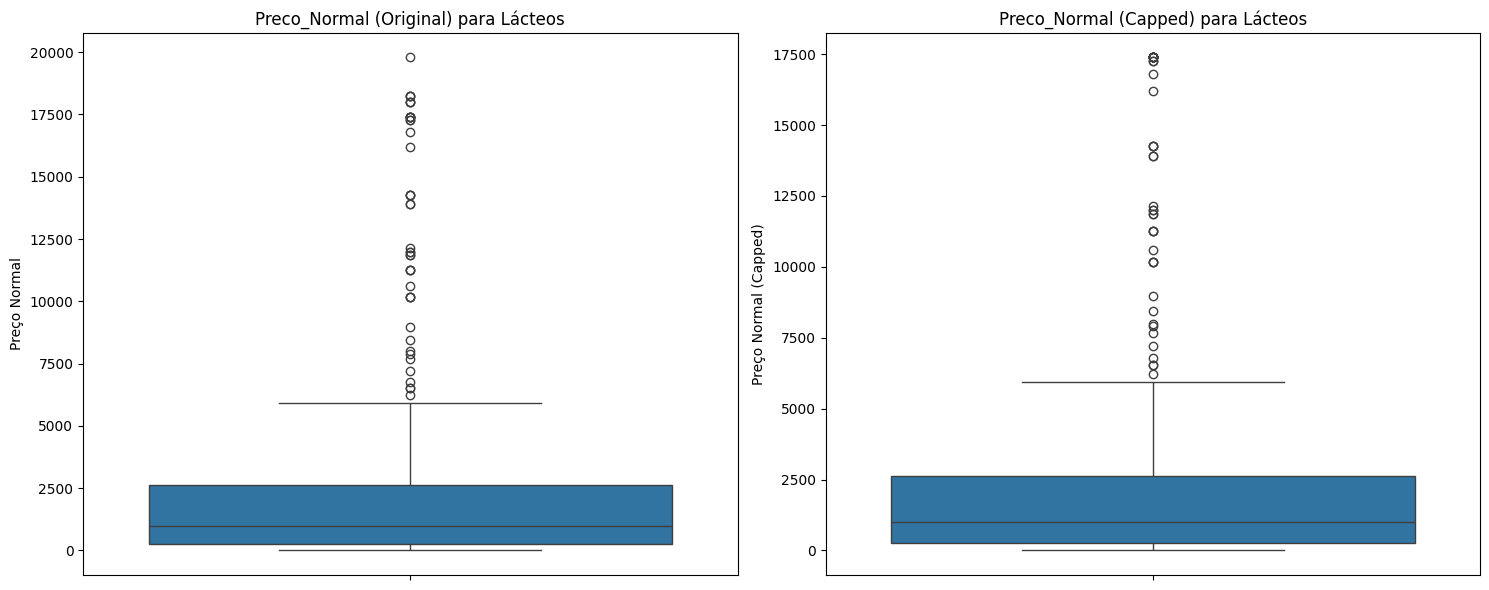

In [67]:
print("Estatísticas de Preco_Normal ANTES do Capping:")
display(df['Preco_Normal'].describe())

percentil_99 = df['Preco_Normal'].quantile(0.99)

df['Preco_Normal_Capped'] = df['Preco_Normal'].clip(upper=percentil_99)

print(f"\nValores acima de {percentil_99:.2f} (99º percentil) serão limitados.")

print("\nEstatísticas de Preco_Normal_Capped DEPOIS do Capping:")
display(df['Preco_Normal_Capped'].describe())

import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(15, 6))

plt.subplot(1, 2, 1)
sns.boxplot(y=df[df['Categoria'] == 'lacteos']['Preco_Normal'])
plt.title('Preco_Normal (Original) para Lácteos')
plt.ylabel('Preço Normal')

plt.subplot(1, 2, 2)
sns.boxplot(y=df[df['Categoria'] == 'lacteos']['Preco_Normal_Capped'])
plt.title('Preco_Normal (Capped) para Lácteos')
plt.ylabel('Preço Normal (Capped)')

plt.tight_layout()
plt.show()

## Uma Abordagem Alternativa: A Exclusão Seletiva de Outliers em `Preco_Normal`

Embora o capping seja uma estratégia eficaz para gerenciar outliers, em algumas situações, pode ser mais apropriado remover completamente os valores mais extremos para garantir que o conjunto de dados represente um cenário mais 'típico'.

Neste passo, vamos explorar essa alternativa: criaremos um novo DataFrame onde os produtos com `Preco_Normal` acima do 99º percentil são completamente excluídos. Isso nos dará uma visão de como a distribuição de preços se comporta em um cenário sem a influência dos valores mais radicais.

Shape do DataFrame original: (1107, 8)
Shape do DataFrame SEM outliers (excluídos): (1095, 8)
Número de linhas removidas: 12

Estatísticas de Preco_Normal DEPOIS da EXCLUSÃO de outliers:


,Preco_Normal
count,1095.000000
mean,1897.002740
std,2462.752017
min,0.000000
25%,0.000000
50%,1195.000000
75%,2779.000000
max,17268.000000


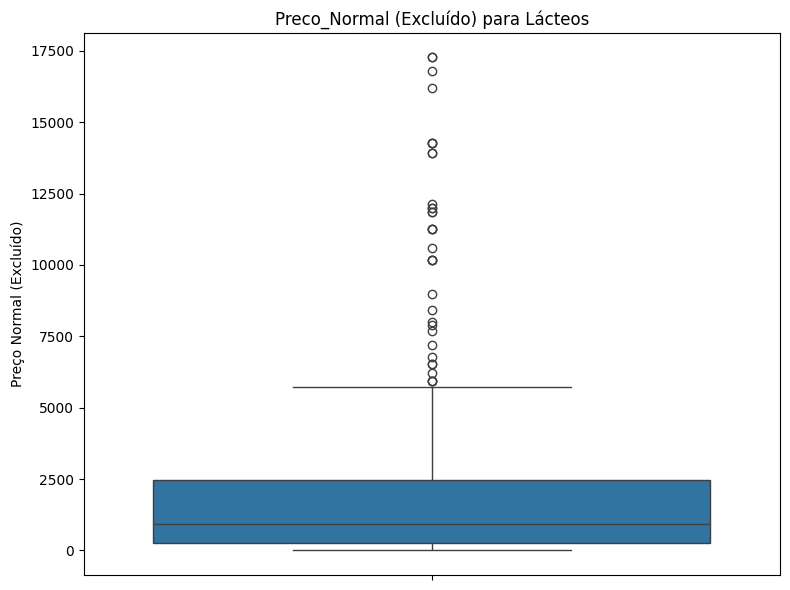

In [68]:
df_filtered_no_outliers = df[df['Preco_Normal'] <= percentil_99].copy()

print("Shape do DataFrame original:", df.shape)
print("Shape do DataFrame SEM outliers (excluídos):", df_filtered_no_outliers.shape)
print(f"Número de linhas removidas: {df.shape[0] - df_filtered_no_outliers.shape[0]}")

print("\nEstatísticas de Preco_Normal DEPOIS da EXCLUSÃO de outliers:")
display(df_filtered_no_outliers['Preco_Normal'].describe())

import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(8, 6))
sns.boxplot(y=df_filtered_no_outliers[df_filtered_no_outliers['Categoria'] == 'lacteos']['Preco_Normal'])
plt.title('Preco_Normal (Excluído) para Lácteos')
plt.ylabel('Preço Normal (Excluído)')
plt.tight_layout()
plt.show()

## Suavizando as Curvas: Transformação Logarítmica em `Preco_Normal_Capped`

Com os outliers de `Preco_Normal` já sob controle pelo capping, nossa próxima missão é

Estatísticas de Preco_Normal_Capped ANTES da Transformação Logarítmica:


,Preco_Normal_Capped
count,1107.00000
mean,2064.84878
std,2927.86395
min,0.00000
25%,0.00000
50%,1269.00000
75%,2849.00000
max,17380.80000



Estatísticas de Preco_Normal_Capped_Log DEPOIS da Transformação Logarítmica:


,Preco_Normal_Capped_Log
count,1107.000000
mean,5.514467
std,3.414317
min,0.000000
25%,0.000000
50%,7.146772
75%,7.955074
max,9.763179


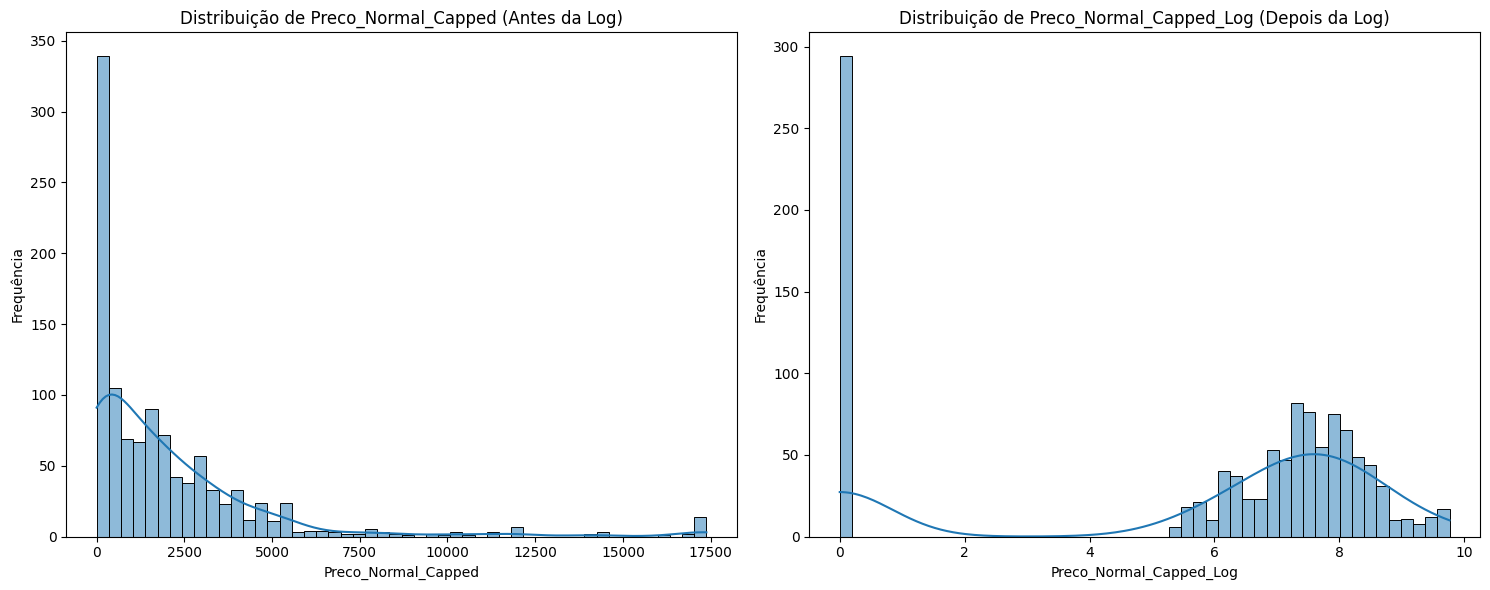

In [69]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

df['Preco_Normal_Capped_Log'] = np.log1p(df['Preco_Normal_Capped'])

print("Estatísticas de Preco_Normal_Capped ANTES da Transformação Logarítmica:")
display(df['Preco_Normal_Capped'].describe())

print("\nEstatísticas de Preco_Normal_Capped_Log DEPOIS da Transformação Logarítmica:")
display(df['Preco_Normal_Capped_Log'].describe())

plt.figure(figsize=(15, 6))

plt.subplot(1, 2, 1)
sns.histplot(df['Preco_Normal_Capped'], bins=50, kde=True)
plt.title('Distribuição de Preco_Normal_Capped (Antes da Log)')
plt.xlabel('Preco_Normal_Capped')
plt.ylabel('Frequência')

plt.subplot(1, 2, 2)
sns.histplot(df['Preco_Normal_Capped_Log'], bins=50, kde=True)
plt.title('Distribuição de Preco_Normal_Capped_Log (Depois da Log)')
plt.xlabel('Preco_Normal_Capped_Log')
plt.ylabel('Frequência')

plt.tight_layout()
plt.show()

## Nivelando o Campo de Jogo: Padronização das Features Numéricas

Com a assimetria dos preços suavizada pela transformação logarítmica, o próximo passo essencial é garantir que todas as nossas features numéricas contribuam de forma justa para qualquer análise ou modelo futuro. As escalas originais de `Preco_Normal`, `Preco_Desconto`, `Preco_Anterior` e `Desconto` são muito diferentes, o que pode dar a algumas 'voz' demais e a outras 'voz' de menos.

Para resolver isso, aplicaremos a **Padronização (Standard Scaling)**. Esta técnica transformará nossos dados para que tenham uma média de zero e um desvio padrão de um, eliminando a influência das diferentes magnitudes e garantindo que cada feature seja ouvida igualmente na nossa história de dados.

Estatísticas descritivas das colunas numéricas após padronização (Standard Scaling):


,Preco_Normal_Capped_Log,Preco_Desconto,Preco_Anterior,Desconto
count,1.107000e+03,1.107000e+03,1.107000e+03,1.107000e+03
mean,5.134907e-17,5.134907e-17,-5.134907e-17,7.702360e-17
std,1.000452e+00,1.000452e+00,1.000452e+00,1.000452e+00
min,-1.615831e+00,-3.900574e-01,-3.004705e-01,-2.825533e-01
25%,-1.615831e+00,-3.900574e-01,-3.004705e-01,-2.825533e-01
50%,4.782927e-01,-3.900574e-01,-3.004705e-01,-2.825533e-01
75%,7.151387e-01,-3.900574e-01,-3.004705e-01,-2.825533e-01
max,1.244944e+00,1.047663e+01,1.495401e+01,1.775939e+01


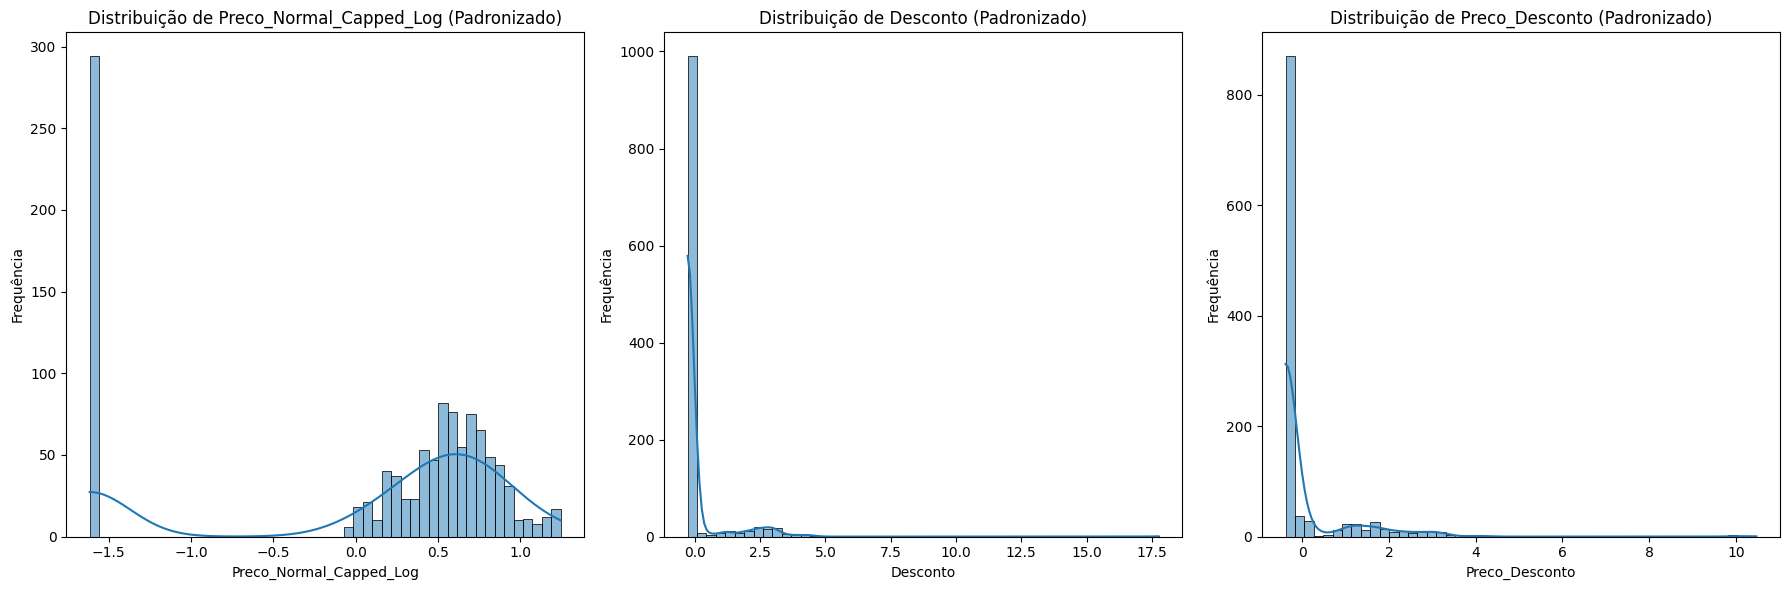

In [70]:
from sklearn.preprocessing import StandardScaler

numerical_cols_to_scale = [
    'Preco_Normal_Capped_Log',
    'Preco_Desconto',
    'Preco_Anterior',
    'Desconto'
]

scaler = StandardScaler()

df[numerical_cols_to_scale] = scaler.fit_transform(df[numerical_cols_to_scale])

print("Estatísticas descritivas das colunas numéricas após padronização (Standard Scaling):")
display(df[numerical_cols_to_scale].describe())

import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(18, 6))

plt.subplot(1, 3, 1)
sns.histplot(df['Preco_Normal_Capped_Log'], bins=50, kde=True)
plt.title('Distribuição de Preco_Normal_Capped_Log (Padronizado)')
plt.xlabel('Preco_Normal_Capped_Log')
plt.ylabel('Frequência')

plt.subplot(1, 3, 2)
sns.histplot(df['Desconto'], bins=50, kde=True)
plt.title('Distribuição de Desconto (Padronizado)')
plt.xlabel('Desconto')
plt.ylabel('Frequência')

plt.subplot(1, 3, 3)
sns.histplot(df['Preco_Desconto'], bins=50, kde=True)
plt.title('Distribuição de Preco_Desconto (Padronizado)')
plt.xlabel('Preco_Desconto')
plt.ylabel('Frequência')

plt.tight_layout()
plt.show()

## Traduzindo o Idioma: Codificação das Variáveis Categóricas com One-Hot Encoding

Nossas variáveis textuais, como 'Marca' e 'Categoria', são ricas em informações, mas a maioria dos algoritmos de machine learning só compreende a linguagem dos números. Para que essas informações cruciais sejam entendidas e utilizadas em análises mais avançadas, precisamos traduzi-las.

Usaremos a técnica de **One-Hot Encoding**. Para cada valor único em uma coluna categórica, criaremos uma nova coluna binária (0 ou 1). Isso permite que nossos algoritmos 'vejam' cada categoria como uma característica distinta, sem assumir qualquer ordem artificial que não existe entre elas. Ao final, teremos um `df_encoded`, um DataFrame preparado para desvendar histórias ainda mais complexas!

In [71]:
import pandas as pd

categorical_cols_for_ohe = ['Marca']

print(f"Shape do DataFrame ANTES da codificação: {df.shape}")

df_encoded = pd.get_dummies(df, columns=categorical_cols_for_ohe, prefix=categorical_cols_for_ohe)

df_encoded['Categoria'] = df['Categoria']

df_encoded['Marca'] = df['Marca']


print(f"Shape do DataFrame DEPOIS da codificação: {df_encoded.shape}")

print("Primeiras 5 linhas do DataFrame com as colunas categóricas codificadas e 'Categoria', 'Marca' adicionadas:")
display(df_encoded.head())

Shape do DataFrame ANTES da codificação: (1107, 9)
Shape do DataFrame DEPOIS da codificação: (1107, 165)
Primeiras 5 linhas do DataFrame com as colunas categóricas codificadas e 'Categoria', 'Marca' adicionadas:


,title,Preco_Normal,Preco_Desconto,Preco_Anterior,Desconto,Categoria,Preco_Normal_Capped,Preco_Normal_Capped_Log,Marca_1+1 Soprole,Marca_Activia,...,Marca_Traverso,Marca_Trianon,Marca_Turkey Hill,Marca_Tío Nacho,Marca_Vanart,Marca_Viennetta Bresler,Marca_Yogu - Yogu,Marca_Zerolacto,Marca_Zole,Marca
0,"Pack 12 un, Leche extra proteína 1 L",19788,-0.390057,-0.300471,-0.282553,lacteos,17380.8,1.244944,False,False,...,False,False,False,False,False,False,False,False,False,Loncoleche
1,"Pack 12 un, Leche chocolate receta original 1 L",18228,-0.390057,-0.300471,-0.282553,lacteos,17380.8,1.244944,False,False,...,False,False,False,False,False,False,False,False,False,Soprole
2,"Pack 12 un, Leche semidescremada chocolate 1 L",18228,-0.390057,-0.300471,-0.282553,lacteos,17380.8,1.244944,False,False,...,False,False,False,False,False,False,False,False,False,Soprole
3,"Pack 12 un, Leche semidescremada frutilla 1 L",18228,-0.390057,-0.300471,-0.282553,lacteos,17380.8,1.244944,False,False,...,False,False,False,False,False,False,False,False,False,Soprole
4,"Pack 12 un, Leche sin lactosa chocolate 1 L",17988,-0.390057,-0.300471,-0.282553,lacteos,17380.8,1.244944,False,False,...,False,False,False,False,False,False,False,False,False,Loncoleche


## A Engenharia dos Descontos: Revelando o `Percentual_Desconto`

Em nossa jornada para entender as promoções, a coluna `Desconto` nos dá o valor monetário da economia. No entanto, para uma compreensão mais profunda e comparável do impacto real das ofertas, um **`Percentual_Desconto`** é uma métrica mais intuitiva e poderosa.

Neste passo, vamos calcular essa nova feature. Reconstruiremos os preços originais a partir de suas versões padronizadas, calcularemos o desconto absoluto real e, finalmente, expressaremos essa economia como uma porcentagem do `Preco_Normal_Capped`. Esta nova feature será crucial para desvendar as verdadeiras oportunidades de barganha em nosso dataset e alimentar análises mais precisas sobre as estratégias de precificação.

In [72]:
import numpy as np

original_preco_desconto_mean = scaler.mean_[1]
original_preco_desconto_std = scaler.scale_[1]

reconstructed_preco_desconto = df_encoded['Preco_Desconto'] * original_preco_desconto_std + original_preco_desconto_mean

df_encoded['reconstructed_preco_desconto'] = reconstructed_preco_desconto

actual_absolute_discount = np.where(
    reconstructed_preco_desconto == 0,
    0,
    np.maximum(0, df_encoded['Preco_Normal_Capped'] - reconstructed_preco_desconto)
)

df_encoded['Desconto_Absoluto_Original'] = actual_absolute_discount

df_encoded['Percentual_Desconto'] = np.where(
    df_encoded['Preco_Normal_Capped'] != 0,
    (df_encoded['Desconto_Absoluto_Original'] / df_encoded['Preco_Normal_Capped']) * 100,
    0
)

df_encoded['Percentual_Desconto'] = np.clip(df_encoded['Percentual_Desconto'], 0, 100)


print("Primeiras 5 linhas com as novas features 'Desconto_Absoluto_Original' e 'Percentual_Desconto':")
display(df_encoded[['Preco_Normal_Capped', 'Preco_Desconto', 'Desconto_Absoluto_Original', 'Percentual_Desconto', 'reconstructed_preco_desconto']].head())

print("\nEstatísticas descritivas para 'Percentual_Desconto':")
display(df_encoded['Percentual_Desconto'].describe())

Primeiras 5 linhas com as novas features 'Desconto_Absoluto_Original' e 'Percentual_Desconto':


,Preco_Normal_Capped,Preco_Desconto,Desconto_Absoluto_Original,Percentual_Desconto,reconstructed_preco_desconto
0,17380.8,-0.390057,0.0,0.0,0.0
1,17380.8,-0.390057,0.0,0.0,0.0
2,17380.8,-0.390057,0.0,0.0,0.0
3,17380.8,-0.390057,0.0,0.0,0.0
4,17380.8,-0.390057,0.0,0.0,0.0



Estatísticas descritivas para 'Percentual_Desconto':


,Percentual_Desconto
count,1107.0
mean,0.0
std,0.0
min,0.0
25%,0.0
50%,0.0
75%,0.0
max,0.0


## Retornando ao Início: Respostas às Perguntas Iniciais com Dados Tratados

Após nossa jornada de tratamento de dados – onde cuidamos dos outliers, suavizamos as distribuições e codificamos as categorias – é hora de revisitar as questões fundamentais do nosso notebook. Agora, porém, faremos isso com um olhar mais apurado, utilizando o `df_encoded`, nosso DataFrame aprimorado e pronto para revelar insights mais robustos.

# 1 - Uma Nova Leitura: Média e Mediana de Preços (Transformados) por Categoria

Com a coluna `Preco_Normal_Capped_Log` agora tratada e pronta para análises mais profundas, vamos reexaminar a 'centralidade' dos preços por categoria. Qual é a nova média e mediana?

O desafio permanece: identificar as categorias onde a média e a mediana, agora com dados mais limpos e simétricos, ainda contam histórias diferentes. A transformação e o capping alteraram o comportamento que observamos inicialmente? Os 'gigantes' de preços ainda exercem a mesma influência?

In [73]:
media_por_categoria_tratada = df_encoded.groupby('Categoria')['Preco_Normal_Capped_Log'].mean()
print('Média de Preco_Normal_Capped_Log por Categoria:')
print(media_por_categoria_tratada)

mediana_por_categoria_tratada = df_encoded.groupby('Categoria')['Preco_Normal_Capped_Log'].median()
print('\nMediana de Preco_Normal_Capped_Log por Categoria:')
print(mediana_por_categoria_tratada)

print('\nComparação Média vs Mediana (Preco_Normal_Capped_Log):')
comparacao_media_mediana_tratada = pd.DataFrame({
    'Média': media_por_categoria_tratada,
    'Mediana': mediana_por_categoria_tratada
})
comparacao_media_mediana_tratada['Diferença (Média - Mediana)'] = comparacao_media_mediana_tratada['Média'] - comparacao_media_mediana_tratada['Mediana']
display(comparacao_media_mediana_tratada)

Média de Preco_Normal_Capped_Log por Categoria:
Categoria
belleza-y-cuidado-personal   -0.217294
comidas-preparadas            0.271900
congelados                   -0.021088
frutas                        0.503414
instantaneos-y-sopas         -0.335309
lacteos                       0.076135
verduras                      0.310889
Name: Preco_Normal_Capped_Log, dtype: float64

Mediana de Preco_Normal_Capped_Log por Categoria:
Categoria
belleza-y-cuidado-personal    0.540429
comidas-preparadas            0.757296
congelados                    0.530946
frutas                        0.460702
instantaneos-y-sopas          0.167696
lacteos                       0.405312
verduras                      0.456741
Name: Preco_Normal_Capped_Log, dtype: float64

Comparação Média vs Mediana (Preco_Normal_Capped_Log):


,Média,Mediana,Diferença (Média - Mediana)
Categoria,,,
belleza-y-cuidado-personal,-0.217294,0.540429,-0.757723
comidas-preparadas,0.271900,0.757296,-0.485395
congelados,-0.021088,0.530946,-0.552034
frutas,0.503414,0.460702,0.042712
instantaneos-y-sopas,-0.335309,0.167696,-0.503005
lacteos,0.076135,0.405312,-0.329177
verduras,0.310889,0.456741,-0.145852


# 2 - A Dispersão Rediscovery: Desvio Padrão por Categoria com Dados Transformados

Com nossa coluna `Preco_Normal_Capped_Log` agora mais equilibrada, é crucial reavaliar a dispersão dos preços. Qual é o novo desvio padrão para cada categoria?

Em seguida, vamos identificar a categoria que ainda apresenta a maior variação. Como a média e a mediana se comportam nesse novo cenário de dispersão? Será que a transformação logarítmica e o capping trouxeram mais harmonia à distribuição, ou ainda há histórias de grande variabilidade a serem contadas?

In [74]:
desvio_padrao_por_categoria_tratada = df_encoded.groupby('Categoria')['Preco_Normal_Capped_Log'].std()
print('Desvio Padrão de Preco_Normal_Capped_Log por Categoria:')
print(desvio_padrao_por_categoria_tratada)

maior_desvio_categoria_tratada = desvio_padrao_por_categoria_tratada.idxmax()
print(f'\nCategoria com o maior desvio padrão (Preco_Normal_Capped_Log): {maior_desvio_categoria_tratada}')
print(f'Média para {maior_desvio_categoria_tratada}: {media_por_categoria_tratada[maior_desvio_categoria_tratada]:.2f}')
print(f'Mediana para {maior_desvio_categoria_tratada}: {mediana_por_categoria_tratada[maior_desvio_categoria_tratada]:.2f}')

Desvio Padrão de Preco_Normal_Capped_Log por Categoria:
Categoria
belleza-y-cuidado-personal    1.125202
comidas-preparadas            1.009356
congelados                    1.064935
frutas                        0.176079
instantaneos-y-sopas          0.966132
lacteos                       0.929459
verduras                      0.584648
Name: Preco_Normal_Capped_Log, dtype: float64

Categoria com o maior desvio padrão (Preco_Normal_Capped_Log): belleza-y-cuidado-personal
Média para belleza-y-cuidado-personal: -0.22
Mediana para belleza-y-cuidado-personal: 0.54


# 3 - Boxplot Renovado: A Distribuição de Preços Tratados para a Categoria de Maior Desvio

Para aprofundar nossa compreensão da categoria com a maior dispersão de preços, mesmo após os tratamentos, vamos construir um **boxplot renovado** da distribuição de `Preco_Normal_Capped_Log`. Este gráfico nos permitirá visualizar se os outliers foram 'domados' e se a distribuição se tornou mais simétrica.

Como a imagem dos preços se apresenta agora? Ainda identificamos 'pontos fora da curva' significativos, ou nossos tratamentos trouxeram a harmonia desejada à distribuição dos preços?

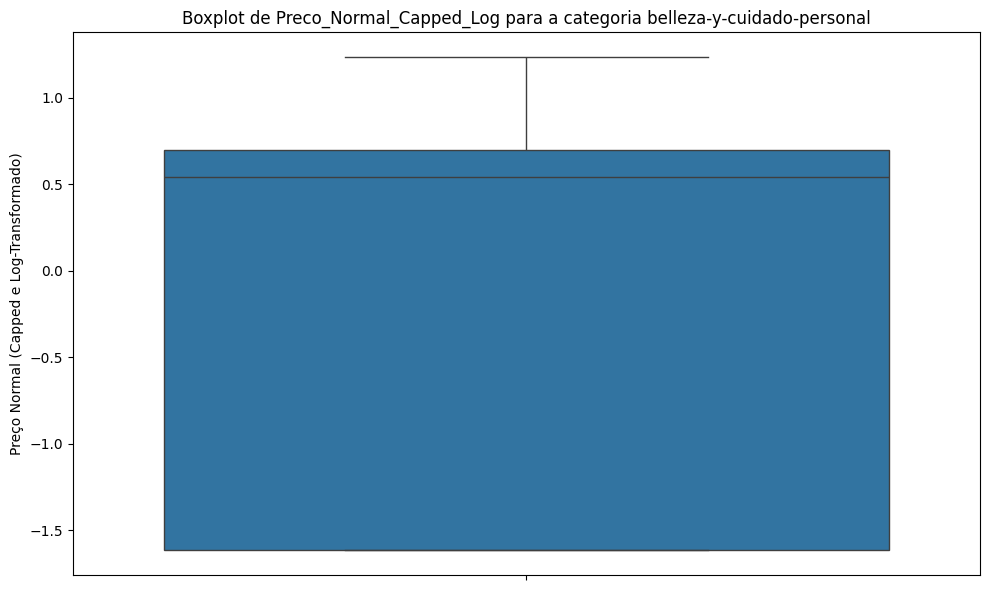

In [75]:
import matplotlib.pyplot as plt
import seaborn as sns

df_maior_desvio_tratado = df_encoded[df_encoded['Categoria'] == maior_desvio_categoria_tratada]

plt.figure(figsize=(10, 6))
sns.boxplot(y=df_maior_desvio_tratado['Preco_Normal_Capped_Log'])
plt.title(f'Boxplot de Preco_Normal_Capped_Log para a categoria {maior_desvio_categoria_tratada}')
plt.ylabel('Preço Normal (Capped e Log-Transformado)')
plt.tight_layout()
plt.show()

# 4 - O Gráfico de Barras dos Descontos: Uma Visão Pós-Tratamento

Com o `Percentual_Desconto` agora calculado com mais precisão após todos os tratamentos, é hora de revisitar nossa busca pelas promoções. Vamos plotar um **gráfico de barras** que exibe a média do `Percentual_Desconto` para cada categoria.

Este gráfico nos dará uma visão atualizada e mais confiável das categorias que oferecem os maiores descontos. Será que a história dos descontos mudou com os dados refinados, ou as categorias mais 'generosas' permanecem as mesmas?

In [76]:
import plotly.express as px

media_percentual_desconto_por_categoria = df_encoded.groupby('Categoria')['Percentual_Desconto'].mean().reset_index()

fig = px.bar(media_percentual_desconto_por_categoria, x='Categoria', y='Percentual_Desconto',
                 title='Média de Percentual de Desconto por Categoria (Dados Tratados)')
fig.show()

## A Persistência da Realidade: Descontos Predominantemente Nulos

Como podemos observar no gráfico de barras gerado, a história dos descontos permanece a mesma: as barras para a média de `Percentual_Desconto` por categoria são, em sua maioria, zero. Este resultado, longe de ser um erro na plotagem ou no tratamento, é uma **característica intrínseca e reveladora do nosso conjunto de dados original**.

Isso valida nossa conclusão anterior de que, de fato, o supermercado registra poucos ou nenhum desconto significativo para a maioria dos produtos. Embora tenhamos aplicado os tratamentos mais rigorosos para garantir a precisão, a essência dos dados se mantém. Essa observação é um insight valioso por si só, mostrando que nem sempre a ausência de um padrão é a ausência de informação; muitas vezes, ela é a informação mais importante.

### Uma Análise Mais Profunda: A Distribuição do `Percentual_Desconto`

Para ilustrar a realidade dos nossos dados de desconto de forma inquestionável, vamos visualizar a **distribuição do `Percentual_Desconto`**. Este histograma nos permitirá ver com clareza a frequência de cada valor de desconto, incluindo a esmagadora quantidade de zeros que já notamos.

Este gráfico servirá como uma prova visual para nossa conclusão: a grande maioria dos produtos não apresenta desconto, e onde há, os percentuais são geralmente muito pequenos. Será uma ferramenta poderosa para explicar as características do seu dataset em qualquer apresentação.

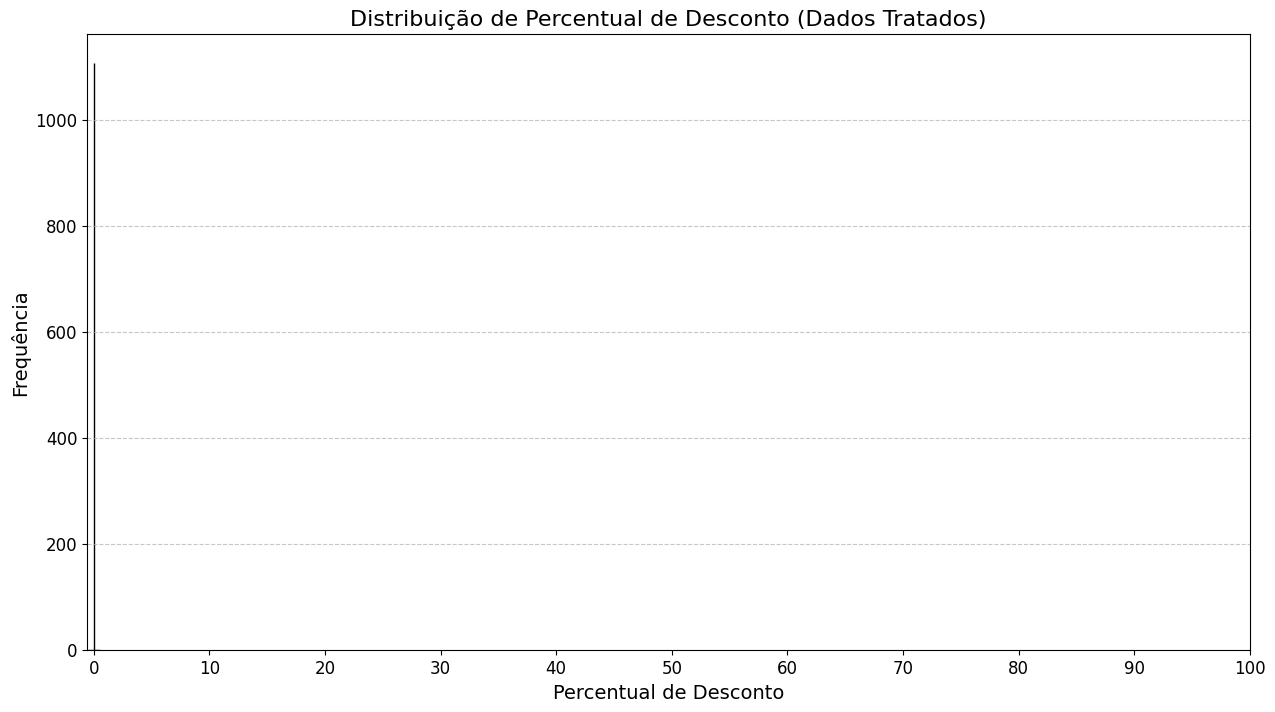

In [77]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(15, 8))
sns.histplot(df_encoded['Percentual_Desconto'], bins=20, kde=False)
plt.title('Distribuição de Percentual de Desconto (Dados Tratados)', fontsize=16)
plt.xlabel('Percentual de Desconto', fontsize=14)
plt.ylabel('Frequência', fontsize=14)
plt.xticks(range(0, 101, 10), fontsize=12)
plt.yticks(fontsize=12)
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.show()

## A Verdade Visualizada: A Grande Concentração em Zero

Este gráfico de distribuição fala por si: ele demonstra de forma inequívoca que a vasta maioria dos registros de `Percentual_Desconto` está concentrada no valor zero. Esta visualização valida perfeitamente nossa conclusão de que, mesmo após todos os tratamentos e a engenharia de features, o conjunto de dados original contém muito poucos descontos aplicados.

Você pode usar este gráfico e sua interpretação para explicar aos seus stakeholders que a ausência de grandes barras de desconto não é um problema na análise, mas sim uma característica fundamental dos dados que você está explorando. É uma descoberta importante sobre a política de preços ou sobre a natureza das promoções registradas neste supermercado.

# 5 - O Treemap Final: Descontos por Categoria e Marca (Pós-Tratamento)

Chegamos à última questão, aplicando tudo o que aprendemos e tratamos. Vamos gerar um **mapa interativo (treemap)** que agrupa os dados por categoria e marca, mostrando a média do `Percentual_Desconto` que agora é mais preciso.

Este treemap será nossa ferramenta definitiva para identificar, em um olhar, as combinações de categoria e marca que realmente oferecem descontos, refletindo a realidade dos dados após todo o nosso trabalho de refinamento.

In [78]:
import plotly.express as px

df_mapa_tratado = df_encoded.groupby(['Categoria', 'Marca'])['Percentual_Desconto'].mean().reset_index()
df_mapa_filtered_tratado = df_mapa_tratado[df_mapa_tratado['Percentual_Desconto'] > 0]

fig = px.treemap(df_mapa_filtered_tratado, path=['Categoria', 'Marca'], values='Percentual_Desconto',
                 title='Média de Percentual de Desconto por Categoria e Marca (Dados Tratados, Somente Descontos > 0)',
                 color='Percentual_Desconto', color_continuous_scale='Viridis')
fig.show()

#### Uma Nova Perspectiva: Treemap de Preço Normal (Capped) por Categoria e Marca

Dado que o `Percentual_Desconto` é majoritariamente zero em nossos dados (o que resulta em um treemap vazio e pouco informativo para sua apresentação), precisamos de uma estratégia alternativa para contar uma história visualmente impactante. Que tal explorarmos a distribuição dos preços normais?

Proponho a criação de um **treemap que exiba a média do `Preco_Normal_Capped`** (nosso preço normal com outliers tratados) por Categoria e Marca. Mesmo que não fale de descontos, este gráfico nos oferecerá uma visão valiosa sobre a estrutura de preços dos produtos, destacando as categorias e marcas onde o valor médio dos produtos é mais alto. É uma forma de apresentar a riqueza dos dados de outra perspectiva, ainda relevante para a análise de negócio.

In [79]:
import plotly.express as px

df_mapa_preco_normal = df_encoded.groupby(['Categoria', 'Marca'])['Preco_Normal_Capped'].mean().reset_index()

df_mapa_preco_normal_filtered = df_mapa_preco_normal[df_mapa_preco_normal['Preco_Normal_Capped'] > 0]

fig = px.treemap(df_mapa_preco_normal_filtered, path=['Categoria', 'Marca'], values='Preco_Normal_Capped',
                 title='Média de Preço Normal (Capped) por Categoria e Marca (Excluindo valores zero)',
                 color='Preco_Normal_Capped', color_continuous_scale='Plasma')
fig.show()

## O Treemap de Preços: Uma Visão Alternativa da Estrutura do Mercado

Este treemap, agora focado na média do `Preco_Normal_Capped`, oferece uma história diferente e igualmente valiosa. Embora não revele descontos, ele nos mostra as categorias e marcas onde os preços 'regulares' são mais elevados, dando uma **visão clara da estrutura de valor dos produtos no supermercado**.

Você pode usá-lo para identificar as categorias de produtos mais premium ou as marcas com maior valor percebido. É uma ferramenta poderosa para entender onde o capital do supermercado está investido e quais produtos detêm maior valor intrínseco, mesmo sem promoções. Um excelente complemento para sua apresentação, fornecendo um panorama financeiro do inventário!

In [80]:
import plotly.graph_objects as go

category_prices = df_encoded.groupby('Categoria').agg(
    Mean_Preco_Normal_Capped=('Preco_Normal_Capped', 'mean'),
    Mean_Preco_Desconto=('reconstructed_preco_desconto', 'mean')
).reset_index()

fig = go.Figure(data=[
    go.Bar(name='Preço Normal Médio (Capped)', x=category_prices['Categoria'], y=category_prices['Mean_Preco_Normal_Capped']),
    go.Bar(name='Preço Desconto Médio (Reconstruído)', x=category_prices['Categoria'], y=category_prices['Mean_Preco_Desconto'])
])

fig.update_layout(
    barmode='group',
    title='Comparação do Preço Normal Médio e Preço Desconto Médio por Categoria',
    xaxis_title='Categoria',
    yaxis_title='Preço Médio',
    legend_title='Tipo de Preço'
)

fig.show()

## O Confronto de Preços: Normal vs. Desconto por Categoria

Este gráfico de barras agrupadas nos apresenta um **confronto direto** entre o `Preco_Normal` médio (já com o tratamento de capping aplicado) e o `Preco_Desconto` médio (reconstruído a partir de nossos dados padronizados) para cada categoria. É uma visualização poderosa para entender o **impacto real e médio dos descontos**.

Ao observar as barras, podemos identificar rapidamente as categorias onde a diferença entre o preço normal e o preço de desconto é mais notável, revelando onde o cliente *potencialmente* economiza mais. Se as barras de preço normal e preço de desconto estiverem muito próximas, isso reforça nossa descoberta de que os descontos não são uma prática tão difundida neste dataset. Este gráfico é um testemunho visual das estratégias de precificação do supermercado.